In [6]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:

import numpy as np
import matplotlib.pyplot as plt

e = 3.795
hbar_c = 1973.0
mc2 = 0.511e6

hbar2_over_2m = (hbar_c**2) / (2 * mc2)


def hamiltonian_matrix(N, dx, potential_values):

    C = hbar2_over_2m / dx**2

    hamiltonian = np.zeros((N, N))

    for i in range(N):

        hamiltonian[i, i] = 2*C + potential_values[i]

        if i > 0:
            hamiltonian[i, i-1] = -C

        if i < N-1:
            hamiltonian[i, i+1] = -C

    return hamiltonian



In [8]:

def screened_colulomb_potential(r, a):

    potential = -e**2 * np.exp(-r/a)/r

    return potential



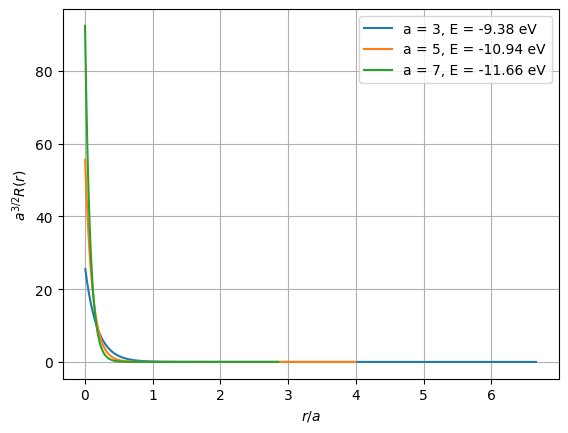

In [9]:

def solve_and_plot(r_max, interior_points, state_number, a):

    if interior_points <= 0:
        raise ValueError("interior_points must be positive.")

    if state_number < 0 or state_number >= interior_points:
        raise ValueError("Invalid state_number.")

    dr = r_max/(interior_points+1)

    r = np.linspace(dr, r_max-dr, interior_points)

    potential = screened_colulomb_potential(r, a)

    hamiltonian = hamiltonian_matrix(interior_points, dr, potential)

    energy, wavevector = np.linalg.eigh(hamiltonian)

    u = wavevector[:, state_number]

    if u[np.argmax(np.abs(u))] < 0:
        u = -u

    norm = np.sum(np.abs(u)**2)*dr

    u_norm = u / np.sqrt(norm)

    # Calculating R
    R = u_norm/r

    return r/a, R*a**1.5, energy[state_number]


r = 20
a = [3, 5, 7]

for i in range(3):

    x, y, energy = solve_and_plot(r, 1000, 0, a[i])

    plt.plot(x, y, label=f"a = {a[i]}, E = {energy:.2f} eV")

plt.xlabel(r"$r/a$")
plt.ylabel(r"$a^{3/2}R(r)$")
plt.legend()
plt.grid(True)
plt.show()
